# Contact maps and interaction energies of TDP-43 with the enzymes

Slab simulations without reactions (`condensate_structure`): full-length TDP-43 (150 chains) or TDP-43 LCD (400 chains),
with 5 copies of calcineurin (`pp3`) or CK1δ (`ck1d-open`), unphosphorylated or with pSer, CALVADOS3 (`CAL3`) or HPS-Urry (`HPSu`).

**Contact maps**: probability that a TDP-43 residue and an enzyme residue are in contact, per pair (TDP-43 chain, enzyme copy),
averaged over the frames `START::STEP` of the replicas `REPLICAS` (sim1, sim2) together. Contact: distance ≤ `CUT_FACTOR` × 2^(1/6) σ_ij, with σ_ij = (σ_i + σ_j)/2 of the
bead types of each chain (pSer beads with the σ of SEP).
- every system is a key `(tdp, pser, enzyme, model)` of `SYSTEMS`; the maps of `COMPUTE` are computed only if their file is
  missing, was made with other settings, or `RECOMPUTE = True`
- one map per replica, `contact_map_{system}_sim{n}.dat`, and the combined map `contact_map_{system}.dat` (average of the
  replicas weighted by their number of frames) in `path_struct_an`, with the settings in the headers; all plots read the
  combined maps
- `SYSTEM` selects the system of the single-system plots, `COMPARE` the pair (unphosphorylated, pSer) of the comparisons

**Energy per residue**: non-bonded energy (Ashbaugh-Hatch + Yukawa) of every TDP-43 and enzyme residue in the droplets
of 200 LCD chains with 5 CK1δ or 5 PP3, computed with `hpa.energy` and saved as CSV files in `path_struct_an`; the files
are read if present, recomputed from the trajectories if missing or with `RECOMPUTE_ENERGY = True`.

In [8]:
import csv
import os
import re
import sys
import time

module_path = os.path.abspath('src')    # run the notebooks from the repository folder
if module_path not in sys.path:
    sys.path.insert(0, module_path)
from hpa.paths import SIM, AN, PL, INPUT_STATS, REPO, STYLES   # data locations (set HPA_DATA_ROOT to use another copy)

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import MDAnalysis as mda
import gsd.hoomd

import hpa.contacts

path_start = INPUT_STATS   # PDB sequences and force fields
path_struct = SIM + 'condensate_structure/'
path_struct_pl = PL + 'condensate_structure/'
path_struct_an = AN + 'condensate_structure/'

## Sequences and force field
Mean mass, total charge, mean σ and λ of the four proteins (unphosphorylated PDB sequences).

In [9]:
def read_pdb_sequence(fn):
    with open(fn) as fh:
        return [line.split()[3] for line in fh if line.split() and line.split()[0] == 'ATOM']


def read_stats(fn):
    '''Force-field file -> {residue type: (mass, charge, sigma [A], lambda)}.'''
    out = {}
    with open(fn) as fh:
        for line in fh:
            f = line.split()
            if f and not f[0].startswith('#'):
                out[f[0]] = tuple(float(x) for x in f[1:5])
    return out


SEQUENCES = {'TDP-43 LCD': read_pdb_sequence(path_start + 'CA_TDP-43_261truncated.pdb'),
             'full TDP-43': read_pdb_sequence(path_start + 'com_full-tdp43_no-helix.pdb'),
             'CK1d': read_pdb_sequence(path_start + 'com_ck1delta-open.pdb'),
             'Calcineurin': read_pdb_sequence(path_start + 'com_pp3.pdb')}
# CALVADOS3 file of the simulations; the HPS-Urry runs used stats_module_HPS-Urry.dat (not on disk), which changes only
# lambda: the sigmas of HPS (stats_module.dat) are identical to these, so the contact cutoffs are the same for both models
STATS = {'CAL3': read_stats(path_start + 'stats_module_CALVADOS3.dat'), 'HPS': read_stats(path_start + 'stats_module.dat')}

for model, ff in STATS.items():
    print(f'--- {model}')
    for name, seq in SEQUENCES.items():
        p = np.array([ff[aa] for aa in seq])
        print(f'{name:12s} {len(seq):4d} residues: mean mass {p[:, 0].mean():7.2f}, total charge {p[:, 1].sum():6.1f}, '
              f'mean sigma {p[:, 2].mean():.3f} A, mean lambda {p[:, 3].mean():.3f}')

--- CAL3
TDP-43 LCD    154 residues: mean mass   98.96, total charge    3.5, mean sigma 5.433 A, mean lambda 0.529
full TDP-43   414 residues: mean mass  108.02, total charge   -1.5, mean sigma 5.673 A, mean lambda 0.459
CK1d          292 residues: mean mass  116.02, total charge   17.0, mean sigma 5.866 A, mean lambda 0.478
Calcineurin   527 residues: mean mass  114.62, total charge   -9.5, mean sigma 5.844 A, mean lambda 0.436
--- HPS
TDP-43 LCD    154 residues: mean mass   98.96, total charge    3.5, mean sigma 5.433 A, mean lambda 0.640
full TDP-43   414 residues: mean mass  108.02, total charge   -1.5, mean sigma 5.673 A, mean lambda 0.653
CK1d          292 residues: mean mass  116.02, total charge   17.0, mean sigma 5.866 A, mean lambda 0.667
Calcineurin   527 residues: mean mass  114.62, total charge   -9.5, mean sigma 5.844 A, mean lambda 0.680


## Contact maps
#### Systems and settings

In [133]:
START, STEP = 500, 20               # frames START, START + STEP, ... up to the end of each dump
REPLICAS = [1, 2]                   # replicas used together (sim1: 5000 frames, sim2: 2500 frames)
CUT_FACTOR = 1.1                    # contact: distance <= CUT_FACTOR * 2^(1/6) * sigma_ij
RECOMPUTE = False                   # True: recompute the replica maps of COMPUTE even if their files are up to date
N_ENZ = 5                           # enzyme copies

TDP = {'150-full-tdp43': dict(file='150-com-full-tdp43', n_chains=150, length=414, first_res=1, label='full TDP-43'),
       '400-tdp43-lcd': dict(file='400-tdp43-lcd', n_chains=400, length=154, first_res=261, label='TDP-43 LCD')}
PSER = {'150-full-tdp43': '-922pser', '400-tdp43-lcd': '-1715pser'}
# enzyme chains as (name, first residue number, length), in bead order
ENZ = {'pp3': dict(length=527, label='Calcineurin', chains=[('CnA', 1, 372), ('CnB', 1, 155)],
                   active_site=[92, 94, 120, 152, 283]),
       'ck1d-open': dict(length=292, label=r'CK1$\delta$', chains=[('CK1d', 3, 292)], active_site=[])}
MODELS = ['CAL3', 'HPSu']

SYSTEMS = [(tdp, pser, enz, model) for tdp in TDP for pser in ('', PSER[tdp]) for enz in ENZ for model in MODELS]
COMPUTE = [key for key in SYSTEMS if key[2] == 'ck1d-open']     # the 8 calcineurin maps; add the ck1d-open keys to compute them


def sys_name(key):
    tdp, pser, enz, model = key
    return f'{tdp}{pser}_5-{enz}_{model}_fr01'


def traj_file(key, rep):
    '''Raw dump of replica rep (the contacts are computed with periodic boundaries: no centring needed).'''
    tdp, pser, enz, model = key
    return (path_struct + f'sim_eq_slab_{tdp}_5-{enz}_{model}_fr01/'
            f'sim{rep}_eq_slab_{TDP[tdp]["file"]}{pser}_5-com-{enz}_{model}_fr01_dump.gsd')


def end_file(key, rep):
    return traj_file(key, rep).replace('_dump.gsd', '_end.gsd')


def map_file(key, rep=None):
    '''Map of one replica, or the combined map of REPLICAS (rep=None).'''
    return path_struct_an + f'contact_map_{sys_name(key)}' + (f'_sim{rep}' if rep else '') + '.dat'


def plot_dir(key):
    tdp, _, enz, _ = key
    return path_struct_pl + f'sim_eq_slab_{tdp}_5-{enz}_fr01/'


def settings_line():
    return f'frames {START}::{STEP}, cutoff {CUT_FACTOR} x 2^(1/6) sigma_ij (bead types of every chain, SEP included)'


def save_fig(fig, key_or_dir, name):
    folder = plot_dir(key_or_dir) if isinstance(key_or_dir, tuple) else key_or_dir
    for ext in ('png', 'pdf'):
        fig.savefig(folder + f'{name}.{ext}', dpi=600)

#### Compute the missing maps
A replica map is computed if its trajectory is there and its file is missing, has no header with the current settings,
was made from fewer frames than the dump now has (simulation still running at the time), or `RECOMPUTE = True` (about 1.5 min for sim1, 1 min for sim2). The combined map is then made from the replica maps, so it
can be rebuilt without the trajectories; a system without replica maps keeps its saved combined map.

In [134]:
def bead_types(key, rep=None):
    '''Bead type names of the TDP-43 chains (n_chains x length) and of one enzyme copy, from the _end.gsd of a replica
    (no reactions: same bead types as the trajectory, same pSer pattern in all replicas; in the Zenodo record).'''
    T, E = TDP[key[0]], ENZ[key[2]]
    if rep is None:
        rep = next((r for r in REPLICAS if os.path.exists(end_file(key, r))), REPLICAS[0])
    with gsd.hoomd.open(end_file(key, rep), 'r') as traj:
        frame = traj[0]
        names = np.asarray(frame.particles.types)[frame.particles.typeid]
    n_1 = T['n_chains'] * T['length']
    if len(names) != n_1 + N_ENZ * E['length']:
        raise ValueError(f'{sys_name(key)}: {len(names)} beads, expected {n_1 + N_ENZ * E["length"]}')
    return names[:n_1].reshape(T['n_chains'], T['length']), names[n_1:n_1 + E['length']]


def header_lines(path):
    with open(path) as fh:
        return [line[2:].rstrip('\n') for line in fh if line.startswith('#')]


def dump_frames(key, rep):
    '''Number of frames of the dump of a replica; None if the trajectory is not there or cannot be read yet
    (simulation or copy still writing it).'''
    if not os.path.exists(traj_file(key, rep)):
        return None
    try:
        with gsd.hoomd.open(traj_file(key, rep), 'r') as traj:
            return len(traj)
    except OSError:
        return None


def map_is_current(key, rep):
    '''Replica map made with the current settings and, if the trajectory is there, from all of its frames
    (a map made while the simulation was still running is recomputed when the dump has grown).'''
    if not os.path.exists(map_file(key, rep)):
        return False
    lines = header_lines(map_file(key, rep))
    if settings_line() not in lines[0]:
        return False
    n_dump = dump_frames(key, rep)
    found = re.search(r'dump of (\d+) frames', lines[1])
    return n_dump is None or (found is not None and int(found.group(1)) == n_dump)


def replica_frames(key, rep):
    '''Number of frames averaged in the map of a replica (second header line: "...; N frames of ...").'''
    return int(re.search(r'(\d+) frames of', header_lines(map_file(key, rep))[1]).group(1))


def compute_replica_map(key, rep):
    T, E = TDP[key[0]], ENZ[key[2]]
    tdp_types, enz_types = bead_types(key, rep)
    sigma = {aa: p[2] / 10 for aa, p in STATS['CAL3'].items()}          # A -> nm
    cut = hpa.contacts.contact_cutoffs(np.vectorize(sigma.get)(tdp_types), np.vectorize(sigma.get)(enz_types), CUT_FACTOR)
    u = mda.Universe(traj_file(key, rep))
    run = hpa.contacts.InterchainContacts(u.atoms, T['n_chains'], N_ENZ, T['length'], E['length'], cut,
                                          verbose=False).run(START, None, STEP)
    n_sep = int(np.sum(tdp_types == 'SEP'))
    header = (f'{settings_line()}\n'
              f'contact probability per residue pair per (TDP-43 chain, enzyme copy); {run.results.n_frames} frames of '
              f'{os.path.basename(traj_file(key, rep))} (dump of {len(u.trajectory)} frames)\n'
              f'rows: {T["label"]} residues {T["first_res"]}-{T["first_res"] + T["length"] - 1}, '
              f'columns: {E["label"]} beads 1-{E["length"]}; {n_sep} pSer')
    np.savetxt(map_file(key, rep), run.results.contact_map, header=header)


def combine_replica_maps(key):
    '''Average of the current replica maps weighted by their frames -> combined map; returns the replicas used.'''
    reps = [r for r in REPLICAS if map_is_current(key, r)]
    if not reps:
        return []
    frames = [replica_frames(key, r) for r in reps]
    combined = sum(f * np.loadtxt(map_file(key, r)) for r, f in zip(reps, frames)) / sum(frames)
    lines = header_lines(map_file(key, reps[0]))
    header = (f'{settings_line()}\n'
              f'contact probability per residue pair per (TDP-43 chain, enzyme copy); replicas '
              f'{", ".join(f"sim{r}" for r in reps)} with {", ".join(map(str, frames))} frames ({sum(frames)} in total), '
              f'weighted by their frames\n{lines[2]}')
    np.savetxt(map_file(key), combined, header=header)
    return list(zip(reps, frames))


for key in COMPUTE:
    print(key)
    for rep in REPLICAS:
        if os.path.exists(traj_file(key, rep)) and dump_frames(key, rep) is None:
            print(f'{sys_name(key)} sim{rep}: dump not readable yet (still being written or copied), skipped')
            continue
        if dump_frames(key, rep) is not None and (RECOMPUTE or not map_is_current(key, rep)):
            t0 = time.time()
            compute_replica_map(key, rep)
            print(f'{sys_name(key)} sim{rep}: computed in {time.time() - t0:.0f} s')
    used = combine_replica_maps(key)
    if used:
        print(f'{sys_name(key)}: combined map of ' + ', '.join(f'sim{r} ({f} frames)' for r, f in used))
    elif os.path.exists(map_file(key)):
        print(f'{sys_name(key)}: WARNING no replica maps (trajectories missing); the saved combined map is used')
    else:
        print(f'{sys_name(key)}: WARNING no trajectories and no saved map')

('150-full-tdp43', '', 'ck1d-open', 'CAL3')
150-full-tdp43_5-ck1d-open_CAL3_fr01: combined map of sim1 (225 frames), sim2 (100 frames)
('150-full-tdp43', '', 'ck1d-open', 'HPSu')
150-full-tdp43_5-ck1d-open_HPSu_fr01: combined map of sim1 (225 frames), sim2 (100 frames)
('150-full-tdp43', '-922pser', 'ck1d-open', 'CAL3')
150-full-tdp43-922pser_5-ck1d-open_CAL3_fr01: combined map of sim1 (225 frames), sim2 (100 frames)
('150-full-tdp43', '-922pser', 'ck1d-open', 'HPSu')
150-full-tdp43-922pser_5-ck1d-open_HPSu_fr01: combined map of sim1 (225 frames), sim2 (100 frames)
('400-tdp43-lcd', '', 'ck1d-open', 'CAL3')
400-tdp43-lcd_5-ck1d-open_CAL3_fr01: combined map of sim1 (225 frames), sim2 (100 frames)
('400-tdp43-lcd', '', 'ck1d-open', 'HPSu')
400-tdp43-lcd_5-ck1d-open_HPSu_fr01: combined map of sim1 (225 frames), sim2 (100 frames)
('400-tdp43-lcd', '-1715pser', 'ck1d-open', 'CAL3')
400-tdp43-lcd-1715pser_5-ck1d-open_CAL3_fr01: combined map of sim1 (225 frames), sim2 (100 frames)
('400-tdp43

#### Loading
`load_map` reads a combined map; residue types come from the `_end.gsd` of a replica (pSer counted as SER in the type
matrices, so that unphosphorylated and pSer systems use the same residues). The pSer percentage is the fraction of the
serines of TDP-43 that are phosphorylated.

In [135]:
def load_map(key):
    return np.loadtxt(map_file(key))


def residue_info(key):
    '''TDP-43 residue types (pSer as SER), enzyme residue types, % of TDP-43 serines phosphorylated.'''
    tdp_types, enz_types = bead_types(key)
    n_sep, n_ser = np.sum(tdp_types == 'SEP'), np.sum(tdp_types == 'SER')
    return np.where(tdp_types[0] == 'SEP', 'SER', tdp_types[0]), enz_types, 100 * n_sep / (n_sep + n_ser)


def enzyme_resnum(enz):
    '''Residue number of every enzyme bead in its own chain, and the bead index where each chain starts.'''
    resnum, starts = [], []
    for name, first, length in ENZ[enz]['chains']:
        starts.append(len(resnum))
        resnum += list(range(first, first + length))
    return np.array(resnum), starts


def enzyme_axis(ax, enz, every=50):
    resnum, starts = enzyme_resnum(enz)
    ticks = [i for i, r in enumerate(resnum) if r % every == 0]
    ax.set_xticks(ticks, resnum[ticks], rotation=90)
    if len(starts) > 1:                        # several chains (calcineurin A, B): separators and names
        for (name, _, _), s in zip(ENZ[enz]['chains'], starts):
            if s > 0:
                ax.axvline(s - 0.5, color='black', lw=1)
            ax.text(s + 5, 0.8, name, fontsize=12, transform=ax.get_xaxis_transform())
    ax.set_xlim(-0.5, len(resnum) - 0.5)
    ax.set_xlabel(f'{ENZ[enz]["label"]} residues')


def tdp_axis(ax, tdp, every=20):
    T = TDP[tdp]
    ticks = np.arange(0, T['length'], every)
    ax.set_xticks(ticks, ticks + T['first_res'], rotation=90)
    ax.set_xlim(-0.5, T['length'] - 0.5)
    ax.set_xlabel(f'{T["label"]} residues')


def tdp_domains(ax, tdp):
    '''NTD, RRM1, RRM2 and LCD of full-length TDP-43 (bead indices).'''
    if tdp != '150-full-tdp43':
        return
    for lo, hi in [(0, 3), (79, 104), (179, 191), (260, 414)]:
        ax.axvspan(lo, hi, color='yellow', alpha=0.2, lw=0)
    for b in [3, 79, 104, 179, 191, 260]:
        ax.axvline(b, color='black', lw=0.65)
    for x, name in [(6, 'NTD'), (107, 'RRM1'), (194, 'RRM2'), (263, 'LCD')]:
        ax.text(x, 0.8, name, fontsize=12, transform=ax.get_xaxis_transform())

#### One system

150-full-tdp43_5-pp3_CAL3_fr01: map (414, 527), 0.0% of the serines phosphorylated, total contact probability per chain pair 0.218


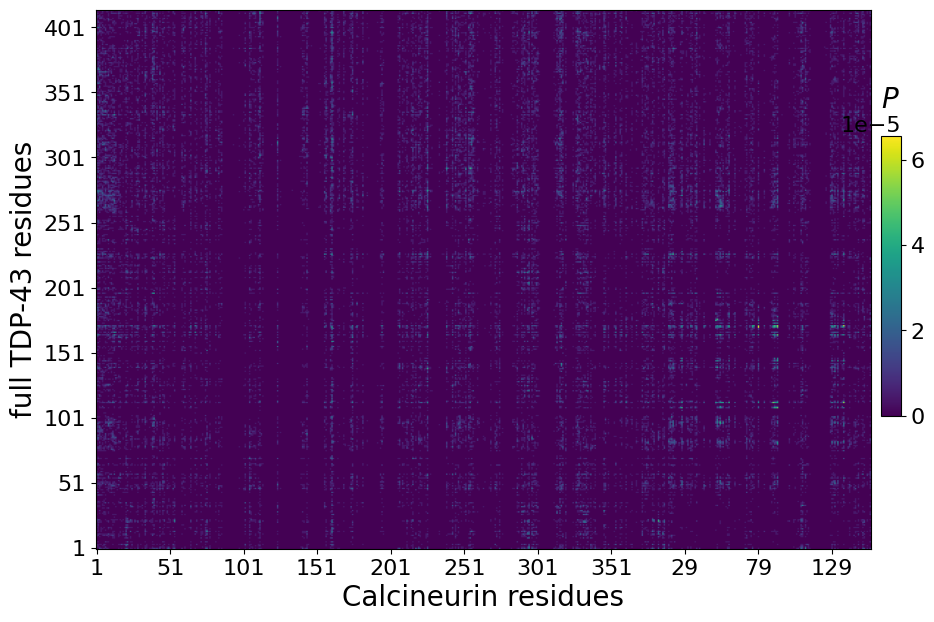

In [180]:
SYSTEM = ('150-full-tdp43', '', 'pp3', 'CAL3')      # (tdp, pser, enzyme, model), one of SYSTEMS

cmap_sys = load_map(SYSTEM)
tdp_seq, enz_seq, pser_pct = residue_info(SYSTEM)
T, E = TDP[SYSTEM[0]], ENZ[SYSTEM[2]]
print(f'{sys_name(SYSTEM)}: map {cmap_sys.shape}, {pser_pct:.1f}% of the serines phosphorylated, '
      f'total contact probability per chain pair {cmap_sys.sum():.3f}')

plt.rc('axes', titlesize=20, labelsize=20)
plt.rc('xtick', labelsize=16)
plt.rc('ytick', labelsize=16)
fig, ax = plt.subplots(figsize=(10, 7))
p = ax.imshow(cmap_sys, origin='lower', cmap='viridis', aspect='auto')
resnum, _ = enzyme_resnum(SYSTEM[2])
ax.set_xticks(np.arange(0, E['length'], 50), resnum[::50])
ax.set_yticks(np.arange(0, T['length'], 50), np.arange(0, T['length'], 50) + T['first_res'])
ax.set_xlabel(f'{E["label"]} residues')
ax.set_ylabel(f'{T["label"]} residues')
fig.subplots_adjust(left=0.075, right=0.85)
cb = plt.colorbar(p, cax=fig.add_axes([0.86, 0.3, 0.02, 0.4]))
cb.ax.set_title(r'$P$')
save_fig(fig, SYSTEM, f'contact_map_{sys_name(SYSTEM)}')

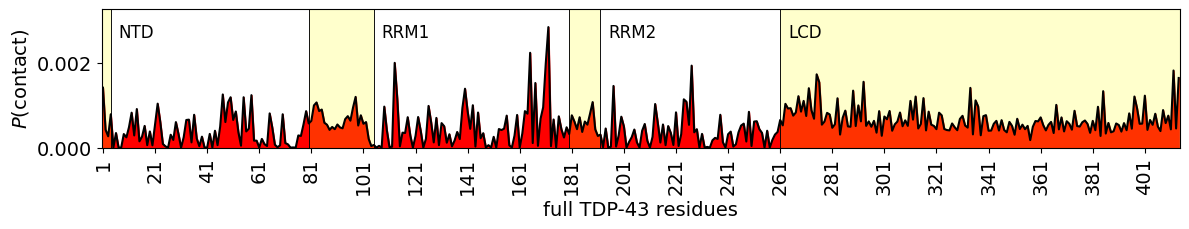

In [181]:
# contact probability of every TDP-43 residue with one enzyme copy (summed over the enzyme residues)
plt.rc('axes', titlesize=14, labelsize=14)
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
fig, ax = plt.subplots(figsize=(12, 2.4))
y = cmap_sys.sum(axis=1)
ax.plot(y, color='black')
ax.fill_between(range(len(y)), 0, y, color='red')
tdp_domains(ax, SYSTEM[0])
tdp_axis(ax, SYSTEM[0])
ax.set_ylabel(r'$P$(contact)')
ax.set_ylim(0, 1.15 * y.max())
fig.tight_layout()
save_fig(fig, SYSTEM, f'contact_map_1Dtdp_{sys_name(SYSTEM)}')

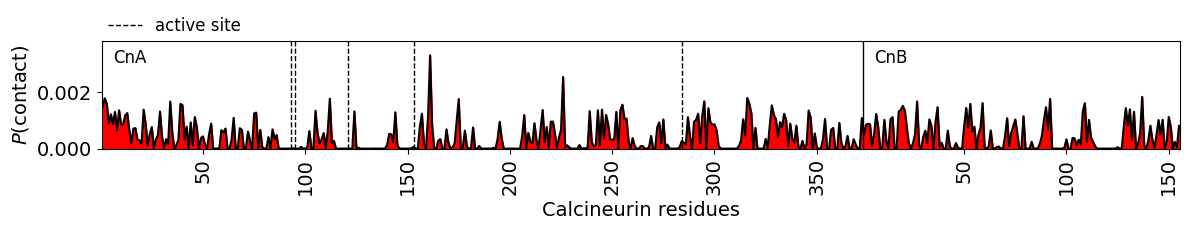

In [182]:
# contact probability of every enzyme residue with one TDP-43 chain (summed over the TDP-43 residues)
fig, ax = plt.subplots(figsize=(12, 2.4))
y = cmap_sys.sum(axis=0)
ax.plot(y, color='black')
ax.fill_between(range(len(y)), 0, y, color='red')
if E['active_site']:
    ax.vlines(E['active_site'], 0, 1, transform=ax.get_xaxis_transform(), color='black', lw=1, ls='--', label='active site')
    ax.legend(loc=(0, 1), frameon=False, fontsize=12)
enzyme_axis(ax, SYSTEM[2])
ax.set_ylabel(r'$P$(contact)')
ax.set_ylim(0, 1.15 * y.max())
fig.tight_layout()
save_fig(fig, SYSTEM, f'contact_map_1Denz_{sys_name(SYSTEM)}')

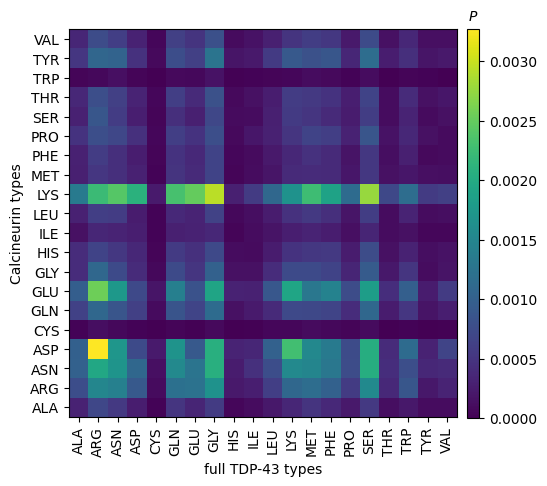

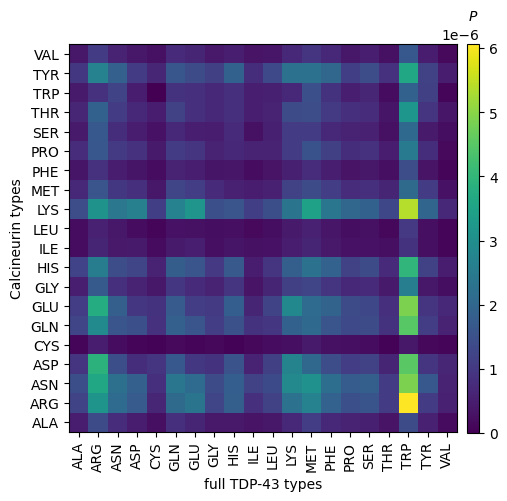

In [183]:
# contacts summed by residue type (pSer counted as SER); normalized: divided by the number of residue pairs of the two types
AA = [aa for aa in STATS['CAL3'] if aa != 'SEP']          # the 20 standard residue types
type_map = np.zeros((len(AA), len(AA)))                   # rows: enzyme type, columns: TDP-43 type
type_map_norm = np.zeros((len(AA), len(AA)))
for i, aa_enz in enumerate(AA):
    for j, aa_tdp in enumerate(AA):
        rows, cols = np.flatnonzero(tdp_seq == aa_tdp), np.flatnonzero(enz_seq == aa_enz)
        if len(rows) and len(cols):
            type_map[i, j] = cmap_sys[np.ix_(rows, cols)].sum()
            type_map_norm[i, j] = type_map[i, j] / (len(rows) * len(cols))

plt.rc('axes', titlesize=10, labelsize=10)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)
for data, tag in [(type_map, 'types'), (type_map_norm, 'types_normalized')]:
    fig, ax = plt.subplots(figsize=(5, 6))
    p = ax.imshow(data, origin='lower', cmap='viridis')
    ax.set_xticks(range(len(AA)), AA, rotation=90)
    ax.set_yticks(range(len(AA)), AA)
    ax.set_xlabel(f'{T["label"]} types')
    ax.set_ylabel(f'{E["label"]} types')
    fig.subplots_adjust(left=0.075, right=0.85)
    cb = plt.colorbar(p, cax=fig.add_axes([0.87, 0.17, 0.025, 0.649]))
    cb.ax.set_title(r'$P$')
    save_fig(fig, SYSTEM, f'contact_map_{tag}_{sys_name(SYSTEM)}')

#### Unphosphorylated vs pSer

400-tdp43-lcd-1715pser_5-pp3_CAL3_fr01: 17.9% of the serines phosphorylated


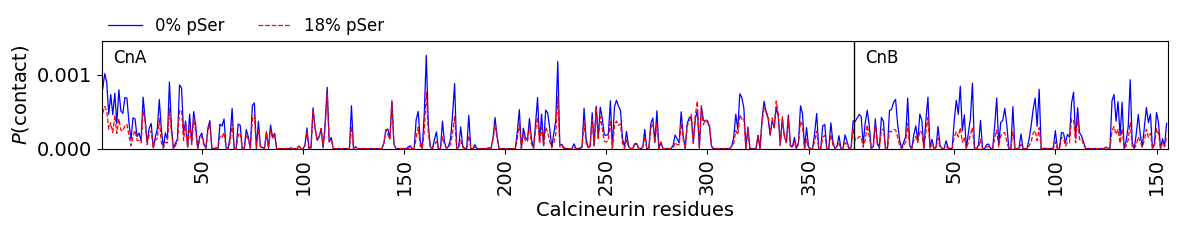

In [94]:
COMPARE = ('400-tdp43-lcd', 'pp3', 'CAL3')      # (tdp, enzyme, model): unphosphorylated vs pSer system

tdp_c, enz_c, model_c = COMPARE
key_0, key_p = (tdp_c, '', enz_c, model_c), (tdp_c, PSER[tdp_c], enz_c, model_c)
map_0, map_p = load_map(key_0), load_map(key_p)
pct_p = residue_info(key_p)[2]
labels_c = ['0% pSer', f'{pct_p:.0f}% pSer']
name_c = f'{tdp_c}_5-{enz_c}_{model_c}_fr01_pser_comparison'
print(f'{sys_name(key_p)}: {pct_p:.1f}% of the serines phosphorylated')

plt.rc('axes', titlesize=14, labelsize=14)
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
fig, ax = plt.subplots(figsize=(12, 2.4))
for m, lab, kw in [(map_0, labels_c[0], dict(ls='-', color='blue')), (map_p, labels_c[1], dict(ls='--', color='red'))]:
    ax.plot(m.sum(axis=0), lw=0.9, label=lab, **kw)
enzyme_axis(ax, enz_c)
ax.set_ylabel(r'$P$(contact)')
ax.set_ylim(0, 1.15 * max(map_0.sum(axis=0).max(), map_p.sum(axis=0).max()))
ax.legend(loc=(0, 1), frameon=False, fontsize=12, ncols=3)
fig.tight_layout()
save_fig(fig, key_0, f'contact_map_1Denz_{name_c}')

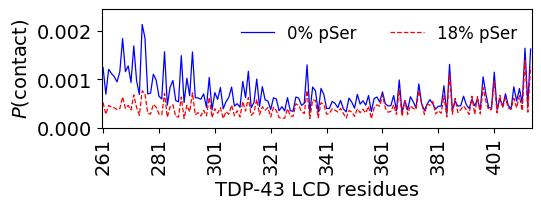

In [95]:
fig, ax = plt.subplots(figsize=(12*0.46, 2.2))
tdp_domains(ax, tdp_c)
for m, lab, kw in [(map_0, labels_c[0], dict(ls='-', color='blue')), (map_p, labels_c[1], dict(ls='--', color='red'))]:
    ax.plot(m.sum(axis=1), lw=0.9, label=lab, **kw)
tdp_axis(ax, tdp_c)
ax.set_ylabel(r'$P$(contact)')
ax.set_ylim(0, 1.15 * max(map_0.sum(axis=1).max(), map_p.sum(axis=1).max()))
ax.legend(frameon=False, fontsize=12, ncols=3)
fig.tight_layout()
save_fig(fig, key_0, f'contact_map_1Dtdp_{name_c}')

## Energy per residue

#### Setup and loading

`ENERGY_SYSTEMS` lists the four simulations. `chains` maps the enzyme beads, in order, to `(chain name, first residue number, length)`:
- CK1δ: one chain, residues 3–294 (`com_ck1delta-open.pdb`)
- Calcineurin: CnA 1–372 followed by CnB 1–155 (`com_pp3.pdb`)

In [33]:
SAVE = True               # write the figures to path_struct_pl
DPI = 600

In [34]:
CK1D = [('CK1d', 3, 292)]
PP3 = [('CnA', 1, 372), ('CnB', 1, 155)]

ENERGY_SYSTEMS = {
    'pp3':       dict(prefix='200-tdp43-lcd_5-pp3',                enzyme='Calcineurin', chains=PP3,
                      title='Calcineurin – unphosphorylated TDP-43'),
    'pp3_pser':  dict(prefix='200-tdp43-lcd-1257pser_5-pp3',       enzyme='Calcineurin', chains=PP3,
                      title='Calcineurin – pSer TDP-43'),
    'ck1d':      dict(prefix='200-tdp43-lcd_5-ck1d-open',          enzyme='CK1δ', chains=CK1D,
                      title='CK1δ – unphosphorylated TDP-43'),
    'ck1d_pser': dict(prefix='200-tdp43-lcd-1257pser_5-ck1d-open', enzyme='CK1δ', chains=CK1D,
                      title='CK1δ – pSer TDP-43'),
}

ONE = {'ALA': 'A', 'ARG': 'R', 'ASN': 'N', 'ASP': 'D', 'CYS': 'C', 'GLN': 'Q',
       'GLU': 'E', 'GLY': 'G', 'HIS': 'H', 'ILE': 'I', 'LEU': 'L', 'LYS': 'K',
       'MET': 'M', 'PHE': 'F', 'PRO': 'P', 'SER': 'S', 'THR': 'T', 'TRP': 'W',
       'TYR': 'Y', 'VAL': 'V', 'SEP': 'B'}

In [41]:
from pathlib import Path

def read_csv(path):
    # CSV -> dict of columns; numeric columns as float arrays, others as lists
    with open(path) as fh:
        rows = list(csv.DictReader(fh))
    out = {}
    for k in rows[0]:
        vals = [r[k] for r in rows]
        try:
            out[k] = np.array([float(v) for v in vals])
        except ValueError:
            out[k] = vals
    return out


def load_tdp(prefix):
    return read_csv(Path(path_struct_an) / f'{prefix}_tdp_per_residue.csv')


def load_enzyme(prefix, chains):
    # enzyme CSV plus per-bead chain name / residue number from `chains`
    d = read_csv(Path(path_struct_an) / f'{prefix}_enzyme_per_residue.csv')
    n = len(d['resname'])
    if sum(c[2] for c in chains) != n:
        raise ValueError(f'chain lengths {chains} do not match {n} enzyme beads in {prefix}')
    d['x'] = d['index_in_copy'].astype(int)          # bead index 1..n, used as x coordinate
    d['chain'], d['resnum'], d['starts'] = [], [], []
    for name, first, length in chains:
        d['starts'].append(len(d['resnum']) + 1)
        d['chain'] += [name] * length
        d['resnum'] += list(range(first, first + length))
    d['resnum'] = np.array(d['resnum'])
    return d


def chain_separators(ax, starts):
    # dashed line between consecutive enzyme chains
    for s in starts[1:]:
        ax.axvline(s - 0.5, color='grey', ls='--', lw=0.8)


def residue_axis(ax, chains, starts, n, label, chain_names=True):
    # ticks every 50 residues in each chain's own numbering; chain names inside the panel
    ticks, ticklab = [], []
    for (name, first, length), s in zip(chains, starts):
        for rn in range(int(np.ceil(first / 50) * 50), first + length, 50):
            ticks.append(s + rn - first)
            ticklab.append(str(rn))
        if len(chains) > 1 and chain_names:
            ax.text(s + length / 2, 0.98, name, transform=ax.get_xaxis_transform(),
                    ha='center', va='top', fontsize=9, weight='bold', color='0.3')
    ax.set_xticks(ticks)
    ax.set_xticklabels(ticklab)
    ax.set_xlim(0, n + 1)
    ax.set_xlabel(label)


def highlighted(tot, n_attr, n_rep):
    # indices of the n_attr most attractive and n_rep most repulsive residues
    order = np.argsort(tot)
    return list(order[:n_attr]) + list(order[len(tot) - n_rep:])


def place_labels(ax, xs, ys, labels, min_dx, fontsize):
    # annotate the points (below them if negative, above if positive); a label closer than min_dx (x units)
    # to an already placed one on the same side is pushed away from zero until they no longer overlap.
    # Call after the y limits are set: label heights are compared in points.
    pt = 72 / ax.figure.dpi
    sep = 1.2 * fontsize                       # minimum vertical distance between labels (points)
    placed = []                                # (x, label height in points, below)
    for xi, yi, lab in sorted(zip(xs, ys, labels)):
        below = yi < 0
        y_pt = ax.transData.transform((xi, yi))[1] * pt
        dy0 = -9 if below else 4
        dy = dy0
        near = [yp for xp, yp, b in placed if b == below and abs(xi - xp) < min_dx]
        while any(abs(y_pt + dy - yp) < sep for yp in near):
            dy += -sep if below else sep
        placed.append((xi, y_pt + dy, below))
        ax.annotate(lab, (xi, yi), xytext=(0, dy), textcoords='offset points', ha='center', fontsize=fontsize,
                    arrowprops=dict(arrowstyle='-', lw=0.4, color='0.5') if dy != dy0 else None)


def save(fig, name, formats=('png',)):
    if SAVE:
        for ext in formats:
            fig.savefig(Path(path_struct_pl) / f'{name}.{ext}', dpi=DPI)
            print(f'Saved {name}.{ext}')

#### Compute or read the energies
For every system, the three files `{prefix}_tdp_per_residue.csv`, `_enzyme_per_residue.csv` and `_timeseries.csv` are read
from `path_struct_an`; they are computed with `hpa.energy.residue_energies` from the trajectory (raw dump, all 2500 frames)
only if a file is missing or `RECOMPUTE_ENERGY = True` (about 3 min per system on 8 processes; needs the trajectories).
The temperature and ionic strength are those of the simulations (250 K, 0.15 M).

In [36]:
import re
import hpa.energy

RECOMPUTE_ENERGY = True   # True: recompute the CSV files from the trajectories even if they exist
# settings of the simulations (temperature, ionic strength) and of the analysis (all frames of the dumps)
ENERGY_SETTINGS = dict(n_chains=200, n_beads=154, tdp_first_resnum=261, n_enzyme=5, temp=250.0, ionic=0.15,
                       start=0, stop=None, stride=1, nblocks=5, nproc=8)
FORCE_FIELD = INPUT_STATS + 'stats_module_CALVADOS3.dat'


def energy_trajectory(prefix):
    '''Raw dump of the droplet simulation of a system, e.g. prefix 200-tdp43-lcd-1257pser_5-pp3.'''
    pser, enz = re.fullmatch(r'200-tdp43-lcd(-\d+pser)?_5-(.+)', prefix).groups()
    return (path_struct + f'sim_eq_200-tdp43-lcd_5-{enz}_CAL3_fr01/'
            f'sim_eq_200-tdp43-lcd{pser or ""}_5-com-{enz}_CAL3_fr01_dump.gsd')


def energy_files(prefix):
    return [f'{path_struct_an}{prefix}_{kind}.csv' for kind in ('tdp_per_residue', 'enzyme_per_residue', 'timeseries')]


for key, s in ENERGY_SYSTEMS.items():
    if RECOMPUTE_ENERGY or not all(os.path.exists(f) for f in energy_files(s['prefix'])):
        t0 = time.time()
        tables = hpa.energy.residue_energies(energy_trajectory(s['prefix']), FORCE_FIELD, **ENERGY_SETTINGS)
        hpa.energy.save_residue_energies(path_struct_an + s['prefix'], tables)
        print(f"{s['prefix']}: computed in {time.time() - t0:.0f} s")
    else:
        print(f"{s['prefix']}: read from the saved CSV files")

sim_eq_200-tdp43-lcd_5-com-pp3_CAL3_fr01_dump.gsd: T = 250.0 K, I = 0.15 M, 200 x 154 TDP-43 beads, 5 x 527 enzyme beads, 2500 frames on 8 processes
  1/2500 frames
  251/2500 frames
  501/2500 frames
  751/2500 frames
  1001/2500 frames
  1251/2500 frames
  1501/2500 frames
  1751/2500 frames
  2001/2500 frames
  2251/2500 frames
200-tdp43-lcd_5-pp3: computed in 138 s
sim_eq_200-tdp43-lcd-1257pser_5-com-pp3_CAL3_fr01_dump.gsd: T = 250.0 K, I = 0.15 M, 200 x 154 TDP-43 beads, 5 x 527 enzyme beads, 2500 frames on 8 processes
  1/2500 frames
  251/2500 frames
  501/2500 frames
  751/2500 frames
  1001/2500 frames
  1251/2500 frames
  1501/2500 frames
  1751/2500 frames
  2001/2500 frames
  2251/2500 frames
200-tdp43-lcd-1257pser_5-pp3: computed in 100 s
sim_eq_200-tdp43-lcd_5-com-ck1d-open_CAL3_fr01_dump.gsd: T = 250.0 K, I = 0.15 M, 200 x 154 TDP-43 beads, 5 x 292 enzyme beads, 2500 frames on 8 processes
  1/2500 frames
  251/2500 frames
  501/2500 frames
  751/2500 frames
  1001/2500 f

In [37]:
# quick overview: totals per system (kJ/mol)
print(f"{'system':12s} {'TDP per chain: inter':>22s} {'intra':>8s} {'enz':>7s}   {'per enzyme copy: AH':>20s} {'YU':>7s} {'TOT':>7s}")
for key, s in ENERGY_SYSTEMS.items():
    t, e = load_tdp(s['prefix']), load_enzyme(s['prefix'], s['chains'])
    print(f"{key:12s} {t['TOT_inter_mean'].sum():22.1f} {t['TOT_intra_mean'].sum():8.1f} "
          f"{t['TOT_enz_mean'].sum():7.2f}   {e['AH_mean'].sum():20.1f} {e['YU_mean'].sum():7.1f} "
          f"{e['TOT_mean'].sum():7.1f}")

system         TDP per chain: inter    intra     enz    per enzyme copy: AH      YU     TOT
pp3                          -135.0   -185.3   -0.35                  -13.3    -0.6   -13.9
pp3_pser                      -89.6   -164.0   -0.23                   -8.7    -0.4    -9.1
ck1d                         -133.7   -185.6   -1.00                  -41.1     1.1   -40.0
ck1d_pser                     -93.9   -163.1   -3.96                 -121.9   -36.5  -158.4


#### 2×2 comparison of the enzymes

Upper left: calcineurin, unphosphorylated · lower left: calcineurin, pSer ·
upper right: CK1δ, unphosphorylated · lower right: CK1δ, pSer.

AH (blue) and Yukawa (red) as lines. The residues with the most attractive / repulsive total energy are circled on
their dominant term and labelled; nearby labels are staggered. Each panel has its own y scale.

In [40]:
ENERGY_SYSTEMS

{'pp3': {'prefix': '200-tdp43-lcd_5-pp3',
  'enzyme': 'Calcineurin',
  'chains': [('CnA', 1, 372), ('CnB', 1, 155)],
  'title': 'Calcineurin – unphosphorylated TDP-43'},
 'pp3_pser': {'prefix': '200-tdp43-lcd-1257pser_5-pp3',
  'enzyme': 'Calcineurin',
  'chains': [('CnA', 1, 372), ('CnB', 1, 155)],
  'title': 'Calcineurin – pSer TDP-43'},
 'ck1d': {'prefix': '200-tdp43-lcd_5-ck1d-open',
  'enzyme': 'CK1δ',
  'chains': [('CK1d', 3, 292)],
  'title': 'CK1δ – unphosphorylated TDP-43'},
 'ck1d_pser': {'prefix': '200-tdp43-lcd-1257pser_5-ck1d-open',
  'enzyme': 'CK1δ',
  'chains': [('CK1d', 3, 292)],
  'title': 'CK1δ – pSer TDP-43'}}

Saved enzyme_per_residue_grid.png
Saved enzyme_per_residue_grid.pdf


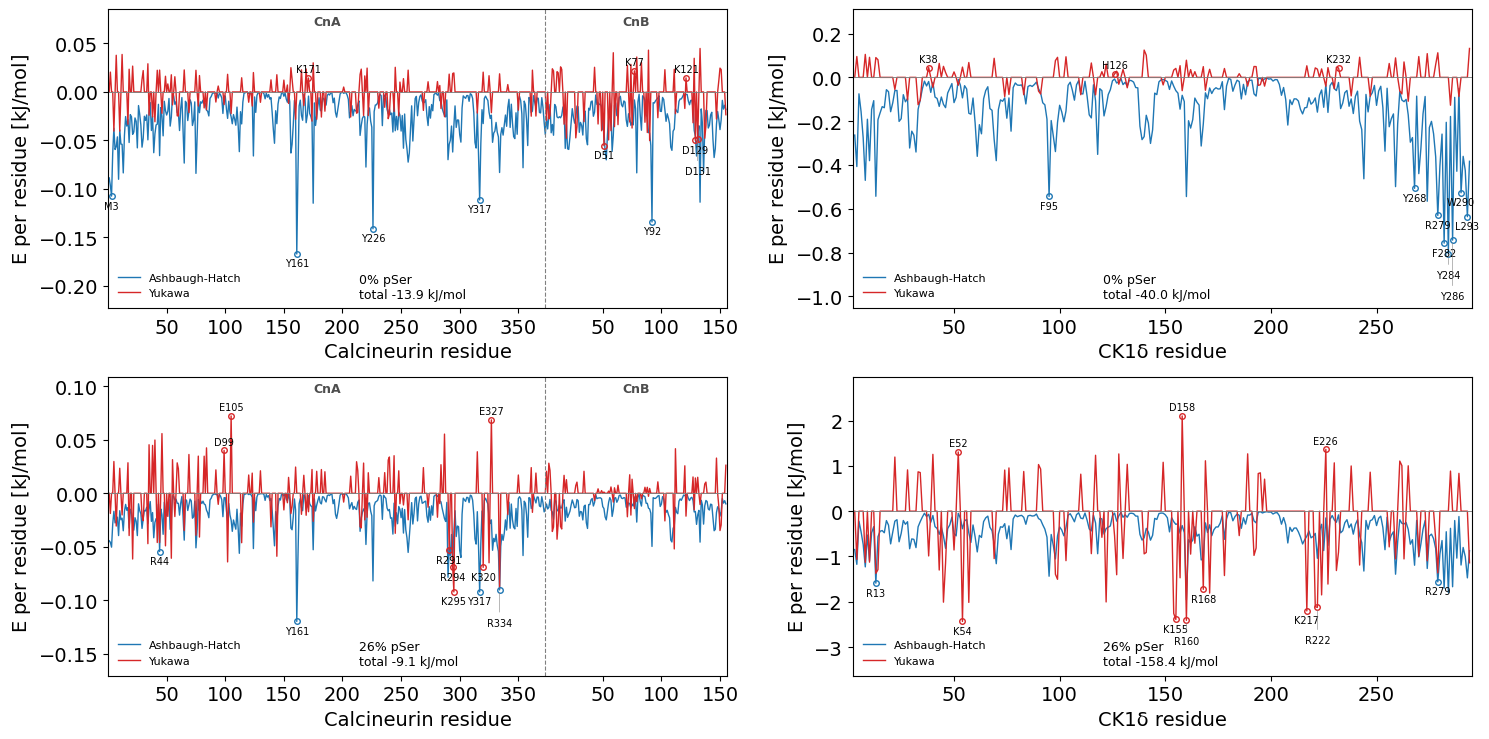

In [59]:
GRID = [(0, 0, 'pp3'), (1, 0, 'pp3_pser'), (0, 1, 'ck1d'), (1, 1, 'ck1d_pser')]


def grid_panel(ax, key, n_attr=8, n_rep=3):
    s = ENERGY_SYSTEMS[key]
    d = load_enzyme(s['prefix'], s['chains'])
    x, ah, yu = d['x'], d['AH_mean'], d['YU_mean']
    tot = ah + yu

    ax.plot(x, ah, color='tab:blue', lw=1.0, label='Ashbaugh-Hatch')
    ax.plot(x, yu, color='tab:red', lw=1.0, label='Yukawa')
    ax.axhline(0, color='grey', lw=0.65)
    chain_separators(ax, d['starts'])

    # highlight residues on their dominant term (AH or Yukawa);
    # chain regions are marked, so labels carry only the resnum
    hl = highlighted(tot, n_attr, n_rep)
    dominant_ah = np.abs(ah[hl]) >= np.abs(yu[hl])
    y_hl = np.where(dominant_ah, ah[hl], yu[hl])
    for xi, yi, is_ah in zip(x[hl], y_hl, dominant_ah):
        ax.plot(xi, yi, 'o', ms=4, mfc='none', mec='tab:blue' if is_ah else 'tab:red', mew=1.0)
    lo, hi = min(ah.min(), yu.min()), max(ah.max(), yu.max(), 0)
    pad = 0.12 * (hi - lo)
    ax.set_ylim(lo - 2.2 * pad, hi + 1.6 * pad)   # room for staggered labels
    place_labels(ax, x[hl], y_hl, [f"{ONE.get(d['resname'][i], 'X')}{d['resnum'][i]}" for i in hl],
                 min_dx=0.035 * len(x), fontsize=7)
    residue_axis(ax, s['chains'], d['starts'], len(x), f"{s['enzyme']} residue")
    ax.set_ylabel('E per residue [$\mathrm{kJ/mol}$]')
    #ax.set_title(f"{s['title']}   (total {tot.sum():.1f} kJ/mol per copy)", fontsize=9.5)
    if s['prefix']=='200-tdp43-lcd_5-pp3' or s['prefix']=='200-tdp43-lcd_5-ck1d-open':
        ax.text((x[-1]-x[0])*0.4, 0.025, f' 0% pSer\n total {tot.sum():.1f} kJ/mol', 
                transform=ax.get_xaxis_transform(),
                ha='left', va='bottom', fontsize=9)
    else:
        ax.text((x[-1]-x[0])*0.4, 0.025, f' 26% pSer\n total {tot.sum():.1f} kJ/mol', 
            transform=ax.get_xaxis_transform(),
            ha='left', va='bottom', fontsize=9)


fig, axs = plt.subplots(2, 2, figsize=(15, 7.5))
for row, col, key in GRID:
    grid_panel(axs[row, col], key)
    axs[row, col].legend(frameon=False, fontsize=8, loc='lower left')
#fig.suptitle('Enzyme residue – TDP-43 LCD interaction energy (per enzyme copy, '
#             'averaged over 5 copies and 2500 frames)', fontsize=10)
fig.tight_layout()
save(fig, 'enzyme_per_residue_grid', formats=('png', 'pdf'))
plt.show()